# WER Challenge

# Inhaltsverzeichnis

- [Vorwort](#vorwort)
- [Einleitung](#einleitung)
- [Definition der Fragestellung](#definition-der-fragestellung)
- [Hypothese](#hypothese)
- [Lösungsstrategie](#lösungsstrategie)

## Einlesen der Datei
- [Allgemeine Übersicht über die Daten](#allgemeine-übersicht-über-die-daten)
- [Bearbeitung der Daten für die Analyse](#bearbeitung-der-daten-für-die-analyse)

## Systemdefinition
- [Definition eines Regentages gemäss WMO-Standard](#definition-eines-regentages-gemäss-wmo-standard)
- [Korrelations Plot](#korrelations-plot)
- [Analyse der Korrelationen](#analyse-der-korrelationen)
  - [Statistische Tests](#statistische-tests)
  - [Hypothesen Tests](#hypothesen-tests)
  - [Zusammenhängende Variablen](#zusammenhängende-variablen)
    - [Der Scope](#der-scope)
    - [Die Gesamtbewölkung](#die-gesamtbewölkung)
    - [Die Luftfeuchtigkeit](#die-luftfeuchtigkeit)
    - [Der Luftdruck](#der-luftdruck)

## Wahrscheinlichkeitsmodell
- [Monte-Carlo-Simulation zur probabilistischen Regenvorhersage](#monte-carlo-simulation-zur-probabilistischen-regenvorhersage)
- [Die Modellarchitektur im Detail](#die-modellarchitektur-im-detail)
- [Validierung und Qualitätssicherung](#validierung-und-qualitätssicherung)
- [Interpretation und praktische Anwendung](#interpretation-und-praktische-anwendung)

## Abhängigkeiten und Unsicherheiten
- [Abhängigkeiten und Unsicherheiten](#abhängigkeiten-und-unsicherheiten)

## Erweiterung durch neue Erkenntnisse
- [Die Jahreszeiten-Faktor Zeit](#die-jahreszeiten-faktor-zeit)
- [Literaturverzeichnis](#literaturverzeichnis)

# Vorwort

Auf dieser Open Mini Challenge haben sich Michaela Brutenic, Roberto Fazekas und Emircan Bagcivan beteiligt.

# Einleitung
Die vorliegende Open Mini Challenge hat als Ziel die Entwicklung eines Wahrscheinlichkeitsmodells, das vorhersagt, ob es am nächsten Tag in Basel regnen wird. Grundlage für die Modellierung bilden regionale Wetterdaten aus den Jahren 2000 bis 2025, die eine Vielzahl meteorologischer Merkmale wie Temperatur, Luftfeuchtigkeit, Luftdruck, Windverhältnisse und Niederschlagsmengen enthalten.

Mithilfe klassischer Methoden der Wahrscheinlichkeitsrechnung – darunter bedingte Wahrscheinlichkeiten, Häufigkeitsverteilungen – soll ein Modell entstehen, das reale Zusammenhänge in den Wetterdaten sichtbar macht und zur quantitativen Vorhersage genutzt werden kann. Die strukturierte Datenlage bietet dafür eine belastbare Grundlage und ermöglicht sowohl explorative Analysen als auch die Entwicklung eines nachvollziehbaren mathematischen Modells mit praktischem Anwendungsnutzen für die Wetterprognose.

# Definition der Fragestellung
Im Zentrum dieser Arbeit steht die folgende Fragestellung:

"Wie hoch ist die Wahrscheinlichkeit für ein Regenereignis am folgenden Tag in Basel basierend auf historischen Wetterdaten?"

Es soll untersucht werden, welche meteorologischen Merkmale mit dem Auftreten von Regenereignissen in Zusammenhang stehen und wie sich diese Zusammenhänge mathematisch modellieren lassen. Die Zielsetzung besteht nicht nur darin, eine binäre Ja-/Nein-Aussage zu treffen, sondern die Wahrscheinlichkeit eines Regens quantitativ zu bestimmen – beispielsweise mit einer Aussage wie: „Die Regenwahrscheinlichkeit für morgen liegt bei 73 %.“ Damit handelt es sich klar um eine probabilistische Fragestellung, die eine datenbasierte Modellierung meteorologischer Zusammenhänge erfordert.

# Hypothese
Es besteht ein signifikanter Zusammenhang zwischen bestimmten meteorologischen Variablen (z.B. Luftfeuchtigkeit, Bewölkung) und der Wahrscheinlichkeit des
Auftretens von Niederschlag. Ein geeignetes Wahrscheinlichkeitsmodell kann verwendet werden, um diesen Zusammenhang zu quantifizieren und zu prognostizieren.


# Lösungsstrategie
Zur Beantwortung der Fragestellung wurde ein mehrstufiger Analyseprozess entwickelt, der sich an gängigen Praktiken der Zeitreihenanalyse und des Feature Engineerings orientiert. Zunächst erfolgte eine systematische Bereinigung und zeitliche Verschiebung der Zielvariable (Niederschlagsmenge des Folgetags), um eine prognosefähige Struktur zu schaffen. Basierend auf der Definition eines Regentages nach WMO-Standard (≥1 mm Niederschlag/Tag) wurde die Zielgröße als binäre Klassifikation interpretiert.

Im nächsten Schritt wurden potenziell erklärende Wettervariablen identifiziert und mittels Korrelationsanalyse sowie Hypothesentests auf ihren Zusammenhang mit dem Auftreten von Regenereignissen untersucht. Dabei kamen sowohl parametrische als auch nichtparametrische Verfahren – abhängig von der Verteilungsstruktur der Daten – zum Einsatz (z. B. Mann-Whitney-U-Test bei fehlender Normalverteilung).

Die Variablen mit dem stärksten statistischen Zusammenhang (Luftdruck, Luftfeuchtigkeit) bildeten die Grundlage für die Konstruktion eines Wahrscheinlichkeitsmodells mittels Monte-Carlo-Simulation. Diese Simulation erlaubt es, durch stochastische Variation der Eingabegrößen eine empirische Verteilung der Regenwahrscheinlichkeit zu erzeugen. Ergänzend wurde der Einfluss saisonaler Effekte geprüft, um potenzielle zeitliche Muster im Modell zu berücksichtigen. Die Kombination dieser Schritte ermöglicht eine datengetriebene, probabilistische Vorhersage der Regenwahrscheinlichkeit für den Folgetag.


# Einlesen der Datei

**Imports**

In [19]:
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr, mannwhitneyu
import distfit as distfit
from IPython.display import display
import seaborn as sns
from scipy import stats
import numpy as np
from datetime import datetime, timedelta


**Einlesen**

In [20]:
df_2000_2025 = pd.read_csv('data/wetterdaten_2000_2025.csv', sep=';')

# Umwandeln des Datums
df_2000_2025['Datum'] = pd.to_datetime(df_2000_2025['Datum'])

### Allgemeine Übersicht über die Daten
Ein grober Überblick über den Datensatz ist essenziell, damit wir wissen, um welche Art von Beobachtungspunkten es sich handelt. Die Daten wurden aus der folgenden Quelle bezogen:  https://data.bs.ch/explore/dataset/100254/table/?disjunctive.jahr&sort=date

In [21]:
df_2000_2025.info()
df_2000_2025.describe()
print("-------------")
print(df_2000_2025.isna().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9254 entries, 0 to 9253
Data columns (total 12 columns):
 #   Column                       Non-Null Count  Dtype         
---  ------                       --------------  -----         
 0   Datum                        9254 non-null   datetime64[ns]
 1   Jahr                         9254 non-null   int64         
 2   Globalstrahlung in W/m2      9254 non-null   float64       
 3   Gesamtschneemenge            9254 non-null   float64       
 4   Gesamtbewölkung              9254 non-null   float64       
 5   Luftdruck in hPa             9254 non-null   float64       
 6   Niederschlag                 9254 non-null   float64       
 7   Sonnenscheindauer            9254 non-null   float64       
 8   Tagesmittel Lufttemperatur   9254 non-null   float64       
 9   Tagesminimum Lufttemperatur  9254 non-null   float64       
 10  Tagesmaximum Lufttemperatur  9254 non-null   float64       
 11  Relative Luftfeuchtigkeit    9254 non-null 

#### Bearbeitung der Daten für die Analyse
Um die Regenwahrscheinlichkeit für den nächsten Tag zu berechnen, müssen wir die Niederschlagsmenge von morgen als Zielvariable verwenden. Dafür verschieben wir die Niederschlagsdaten um einen Tag nach vorne, damit sie zur jeweils aktuellen Zeile passen. Diese zeitliche Verschiebung ist zwar für Vorhersagemodelle sinnvoll, kann aber bei anderen Analysen, z.B. bei der Untersuchung von Zusammenhängen in der Originalzeitreihe, zu Problemen führen.

Deshalb speichern wir die verschobenen Daten in einer separaten Excel-Datei. So können wir je nach Analyse entweder mit den Originaldaten oder den verschobenen Daten arbeiten. Das hilft uns, Fehler in der Analyse zu vermeiden und flexibel zwischen verschiedenen Ansätzen zu wechseln.

Dieses Vorgehen orientiert sich an gängigen Praktiken im Feature Engineering bei Zeitreihendaten (siehe z.Hyndman, R. J., & Athanasopoulos, 2018:, 2nd ed., https://otexts.com/fpp2/).

In [22]:
df_mit_shift = df_2000_2025.copy(deep=True)
df_mit_shift['Niederschlag_Morgen'] = df_mit_shift['Niederschlag'].shift(-1)
df_mit_shift = df_mit_shift.drop(columns=['Niederschlag'])
df_mit_shift = df_mit_shift.dropna(subset=['Niederschlag_Morgen'])
df_mit_shift.to_csv('data/mit_shift.csv', index=False, sep=';')

# Systemdefinition

Um unsere Hypothese gezielt untersuchen zu können, ist es sinnvoll, den Umfang der Daten einzugrenzen. Da nicht alle Informationen im Datensatz für unsere Fragestellung relevant sind, benötigen wir eine fundierte Entscheidungsgrundlage dafür, auf welche Variablen wir uns konzentrieren.

Ein geeigneter erster Schritt ist die Analyse der Korrelationen innerhalb des Datensatzes. Dabei interessiert uns insbesondere, welche Variablen am stärksten mit dem Niederschlag zusammenhängen. Zwar erlaubt die Korrelation noch keine Aussage über kausale Zusammenhänge, liefert jedoch wertvolle Hinweise darauf, wo sich ein genauerer Blick lohnt – sie dient also gewissermassen als erste Fährte in der Datenexploration.

#### Definition eines Regentages gemäss WMO-Standard

Für die statistische Analyse von Wahrscheinlichkeitsverteilungen des Niederschlags empfiehlt sich die Verwendung der Definition eines Regentages nach den Standards der Weltorganisation für Meteorologie (WMO). Demnach gilt ein Tag als Regentag, wenn eine tägliche Niederschlagsmenge von mindestens 1,0 mm gemessen wird.

Diese Definition ist international anerkannt und ermöglicht vergleichbare klimatologische Auswertungen über verschiedene geografische Regionen hinweg. Sie stellt eine sinnvolle Abgrenzung dar, da leichtere Niederschläge unterhalb dieser Schwelle oft nicht signifikant zur Gesamtklimabilanz beitragen. (Quelle: WMO Guidelines on the Calculation of Climate Normals, https://www.agroorbi.pt/livroagrometeorologia/DocsProg/Temas%26Exerc%C3%ADciosExtraPorCap%C3%ADtulo/Cap1_Introdu%C3%A7%C3%A3o/Docs/WMO%20Guidelines%20on%20the%20Calculation%20of%20Climate%20Normals_en.pdf)


In [23]:
# Kategorisierung der Niederschlagsmenge
def categorize_Regentag(rain_in_mm):
    if rain_in_mm == 0:
        return "Kein Regentag"
    elif 0 < rain_in_mm < 5:
        return "Leichter Regentag"
    else:
        return "Starker Regentag"


df_2000_2025["Regentag_Kategorie"] = df_2000_2025["Niederschlag"].apply(categorize_Regentag)
df_mit_shift["Regentag_Kategorie"] = df_mit_shift["Niederschlag_Morgen"].apply(categorize_Regentag)
df_2000_2025["Regentag_Kategorie"].describe()

count              9254
unique                3
top       Kein Regentag
freq               4981
Name: Regentag_Kategorie, dtype: object

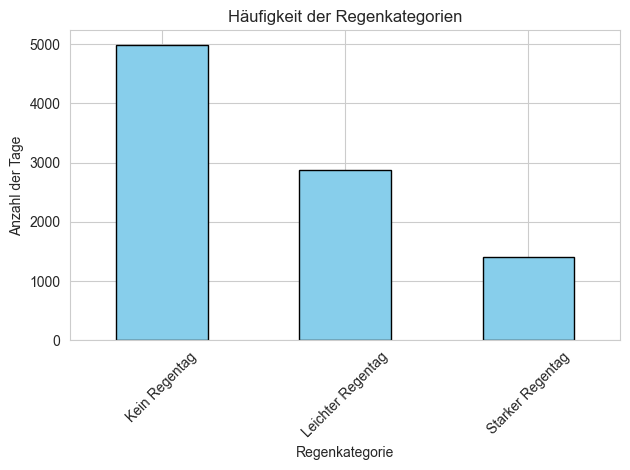

In [24]:
# Häufigkeiten zählen
regen_counts = df_2000_2025["Regentag_Kategorie"].value_counts()

# Balkendiagramm plotten
regen_counts.plot(kind="bar", color="skyblue", edgecolor="black")
plt.title("Häufigkeit der Regenkategorien")
plt.xlabel("Regenkategorie")
plt.ylabel("Anzahl der Tage")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Korrelations Plot

Um die Auswahl der Variablen fundiert treffen zu können, untersuchen wir die Korrelationen zwischen den einzelnen
Beobachtungen. Unsere Wahl fällt dann auf die Beobachtung, die einerseits die höchste Korrelation mit dem
Niederschlag hat und andererseits aus meteorologischer Sicht sinnvoll ist.

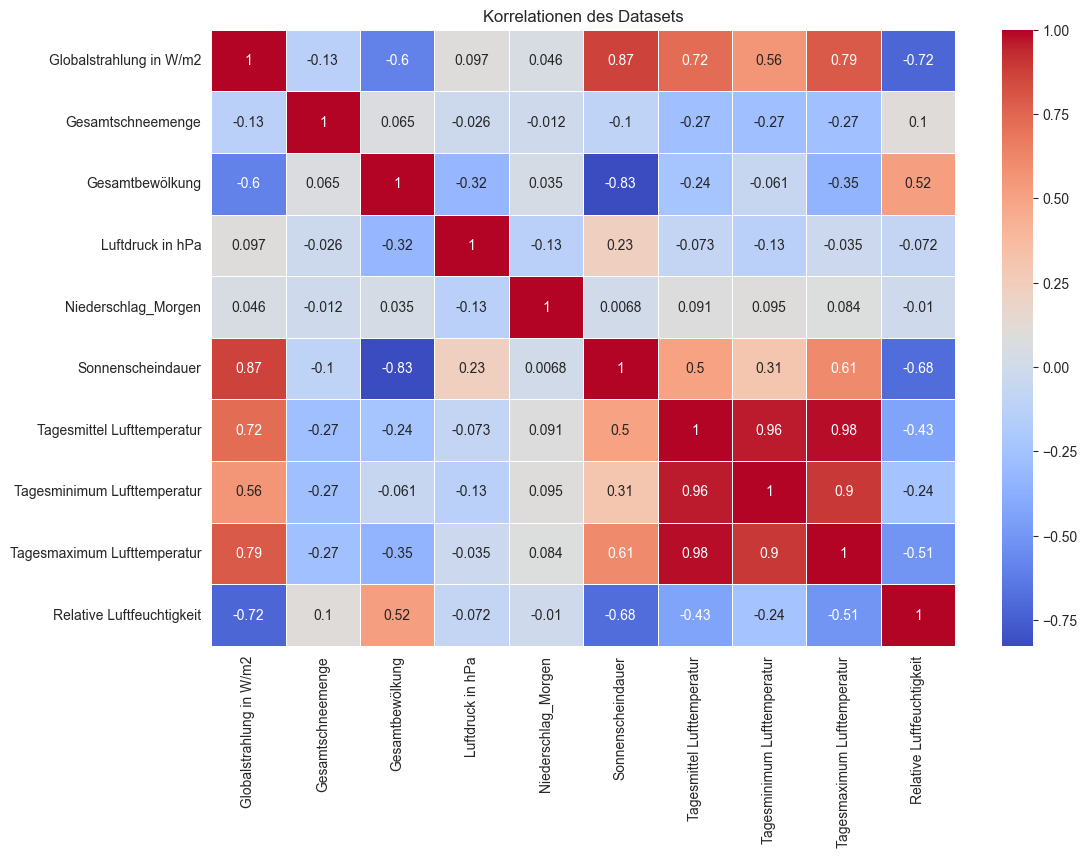

In [25]:
# Zusammenfügen der Daten über die letzten fünf Jahre
df_2000_2025_for_corr = df_mit_shift[[
    'Globalstrahlung in W/m2',
    'Gesamtschneemenge',
    'Gesamtbewölkung',
    'Luftdruck in hPa',
    'Niederschlag_Morgen',
    'Sonnenscheindauer',
    'Tagesmittel Lufttemperatur',
    'Tagesminimum Lufttemperatur',
    'Tagesmaximum Lufttemperatur',
    'Relative Luftfeuchtigkeit'
]].copy(deep=True)

# Korrelationen erkennen
df_correlation = df_2000_2025_for_corr.corr()

plt.figure(figsize=(12, 8))
sns.heatmap(df_correlation, annot=True, cmap='coolwarm', linewidths=.5)
plt.title("Korrelationen des Datasets")
plt.show()

## Analyse der Korrelationen
Zur Verbesserung der Übersichtlichkeit werden die berechneten Korrelationskoeffizienten nach ihrer Stärke in absteigender Reihenfolge sortiert und anschliessend in einem Balkendiagramm (Barplot) visualisiert.

Tagesminimum Lufttemperatur    0.094870
Tagesmittel Lufttemperatur     0.090522
Tagesmaximum Lufttemperatur    0.084133
Globalstrahlung in W/m2        0.046287
Gesamtbewölkung                0.035055
Name: Niederschlag_Morgen, dtype: float64


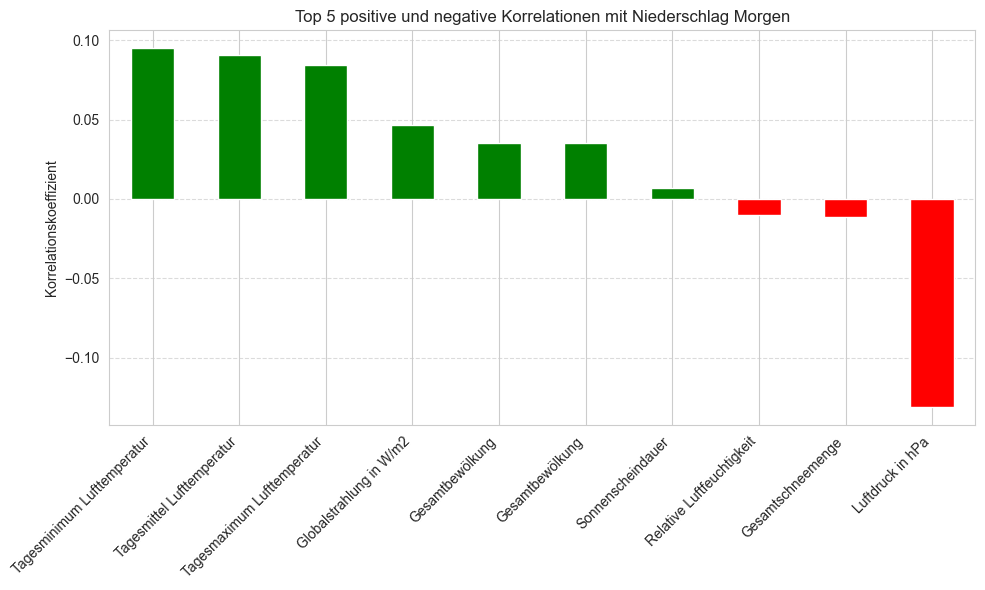

In [26]:
# Höchste wie tiefste Korrelationen
df_correlation_highest = (df_correlation["Niederschlag_Morgen"].drop("Niederschlag_Morgen")
                          .sort_values(ascending=False)).head(5)
print(df_correlation_highest)
df_correlation_lowes = (df_correlation["Niederschlag_Morgen"]
                        .drop("Niederschlag_Morgen").sort_values(ascending=True)).head(5)

# Zusammenfügen der DF's
combined_corr = (pd.concat([df_correlation_highest, df_correlation_lowes])
                 .sort_values(ascending=False))

# Plotten der Korrelationen
plt.figure(figsize=(10, 6))
combined_corr.plot(kind='bar', color=['green' if corr > 0 else 'red' for corr in combined_corr.values])
plt.title("Top 5 positive und negative Korrelationen mit Niederschlag Morgen")
plt.ylabel("Korrelationskoeffizient")
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

### Statistische Tests:
Zur statistischen Überprüfung eines linearen Zusammenhangs zwischen den gewählten Variablen kommt der Spearman-Test zum Einsatz. Der dabei berechnete Korrelationskoeffizient r quantifiziert, sowohl die Richtung als auch die Stärke des linearen Zusammenhangs zwischen zwei metrischen Variablen.

In [27]:
# Mit Spearman die Variablen herausfinden
results = []
numerical_cols = df_mit_shift.select_dtypes(include='number').columns

for col in numerical_cols:
    if col != 'Niederschlag_Morgen':
        rho, p = spearmanr(df_mit_shift[col], df_mit_shift['Niederschlag_Morgen'])
        results.append({
            'Variable': col,
            'Spearman-Korrelation': rho,
            'p-Wert': p,
            'Signifikant (p<0.05)': p < 0.05
        })

df_results = pd.DataFrame(results)
df_results.sort_values(by='Spearman-Korrelation', ascending=False, inplace=True)
display(df_results)

,Variable,Spearman-Korrelation,p-Wert,Signifikant (p<0.05)
3,Gesamtbewölkung,0.112160,2.719532e-27,True
9,Relative Luftfeuchtigkeit,0.044513,1.840526e-05,True
7,Tagesminimum Lufttemperatur,0.036960,3.764623e-04,True
6,Tagesmittel Lufttemperatur,0.015843,1.275468e-01,False
2,Gesamtschneemenge,0.000707,9.457972e-01,False
8,Tagesmaximum Lufttemperatur,0.000147,9.887237e-01,False
0,Jahr,-0.013107,2.074217e-01,False
1,Globalstrahlung in W/m2,-0.052267,4.892979e-07,True
5,Sonnenscheindauer,-0.084221,4.867737e-16,True
4,Luftdruck in hPa,-0.229043,2.036051e-110,True


Beim Blick auf den Korrelations-Plot fällt auf, dass die Gesamtbewölkung sowie der Luftdruck die stärksten Korrelationen mit dem Niederschlag aufweisen – positiv bzw. negativ. Ebenfalls auffällig sind die relative Luftfeuchtigkeit und die Sonnenscheindauer, die im Vergleich zu den übrigen Variablen sowohl relativ hohe als auch niedrige Korrelationswerte zeigen.

Die restlichen Variablen liegen mit ihren Korrelationswerten nahe bei null. Dies bedeutet nicht zwangsläufig, dass kein Zusammenhang besteht – vielmehr lässt sich kein linearer Zusammenhang nachweisen. Nicht-lineare Beziehungen können durch die Pearson-Korrelation nicht abgebildet werden und müssten gegebenenfalls mit anderen Methoden untersucht werden.

### Hypothesen Tests
Um genauer zu überprüfen, ob die ausgewählten Variablen tatsächlich einen Einfluss auf die Regenwahrscheinlichkeit haben, können Hypothesentests herangezogen werden. Die Auswahl eines geeigneten Tests setzt jedoch voraus, dass die Verteilung der beteiligten Variablen im Vorfeld genauer untersucht wird. Insbesondere ist zu prüfen, ob die Variablen normalverteilt sind oder ob alternative Verteilungen vorliegen – da dies direkten Einfluss auf die Wahl zwischen parametrischen und nichtparametrischen Testverfahren hat.

#### Analyse der Verteilung

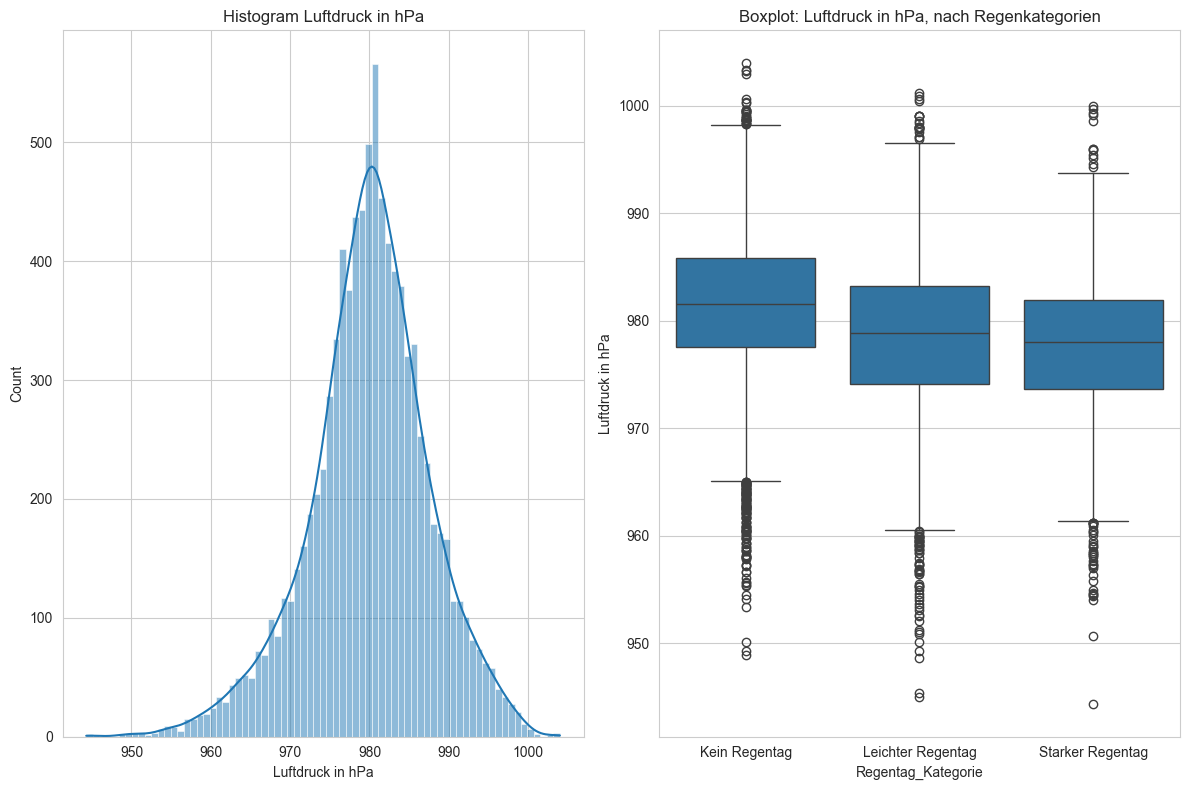

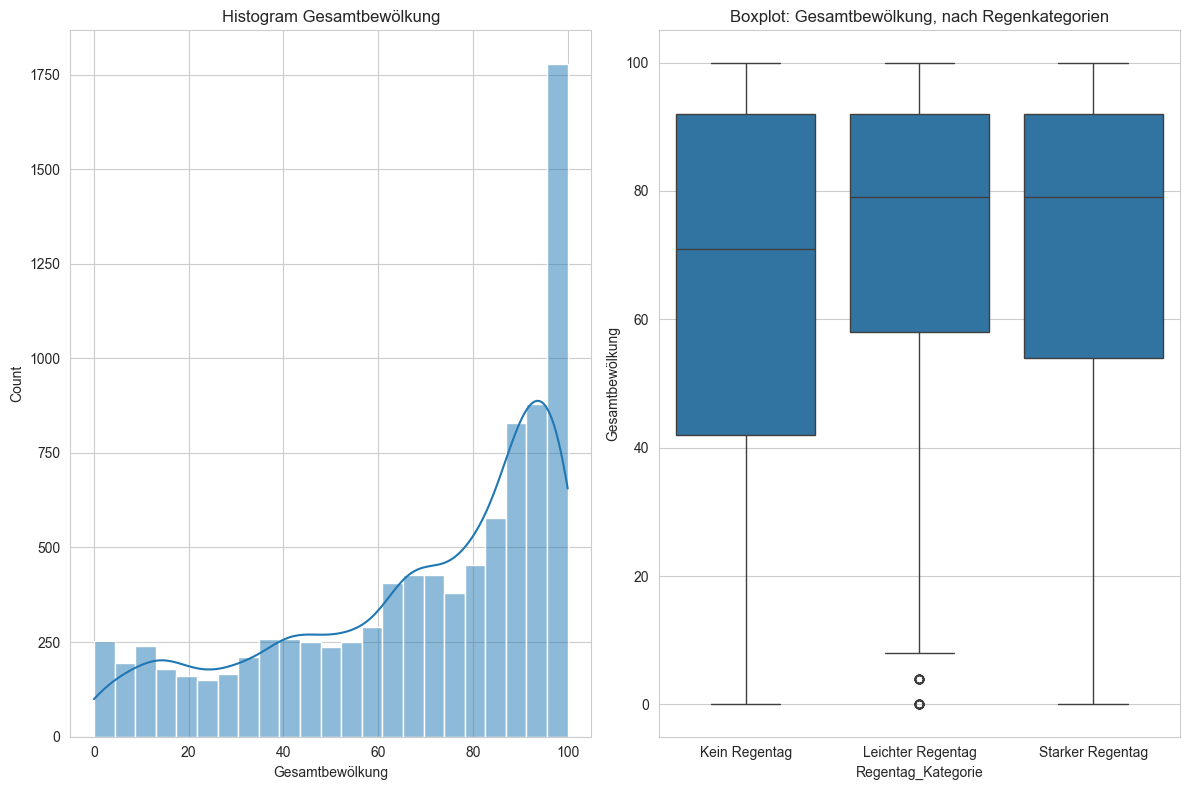

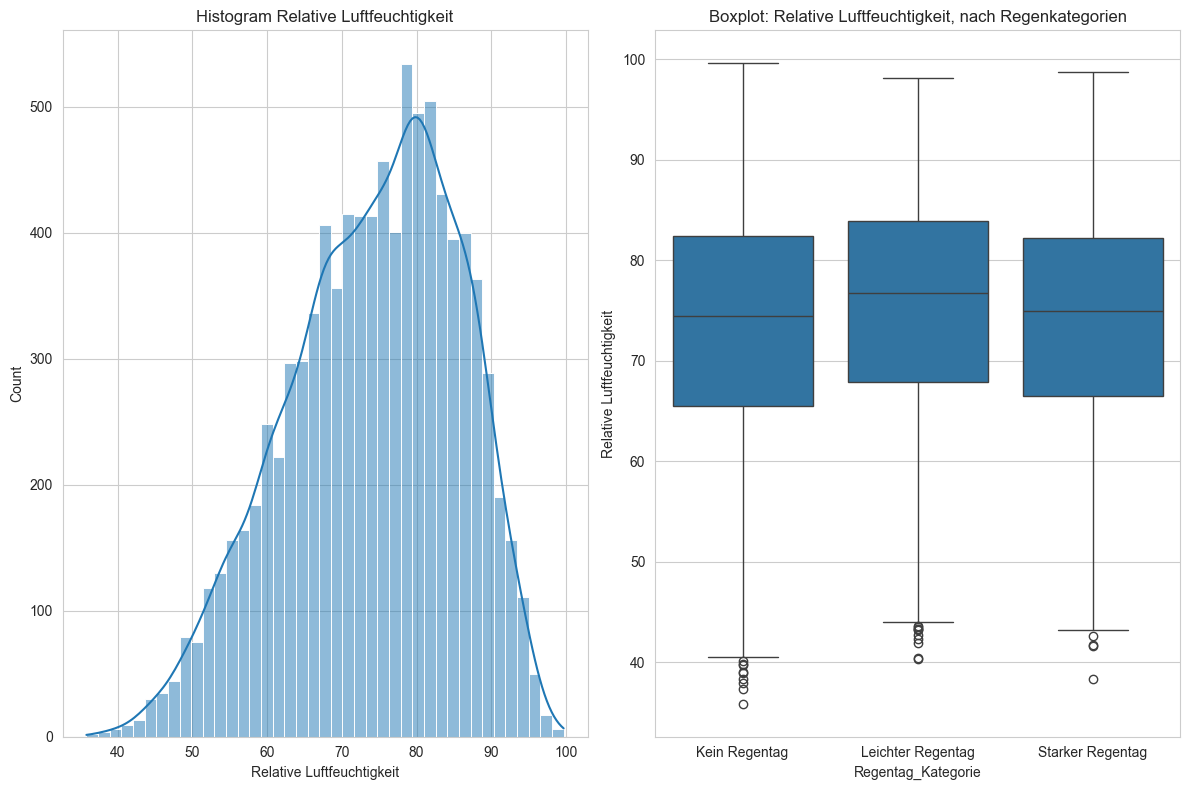

In [28]:
for col in ['Luftdruck in hPa', 'Gesamtbewölkung', 'Relative Luftfeuchtigkeit']:
    plt.figure(figsize=(12, 8))

    plt.subplot(1, 2, 1)
    sns.histplot(df_mit_shift[col], kde=True)
    plt.title(f'Histogram {col}')

    plt.subplot(1, 2, 2)
    sns.boxplot(x="Regentag_Kategorie", y=col, data=df_mit_shift)
    plt.title(f'Boxplot: {col}, nach Regenkategorien')

    plt.tight_layout()
    plt.show()

Bevor ein T-Test angewendet werden kann, ist zu überprüfen, ob die zugrunde liegenden Variablen normalverteilt sind. Liegt keine Normalverteilung vor, ist der T-Test nicht geeignet – in diesem Fall kommen alternative, nichtparametrische Testverfahren zum Einsatz, auf die im weiteren Verlauf der Analyse eingegangen wird.


In [29]:
# Aufteilen in zwei Gruppen Regen oder kein Regen für den ersten Test.
# Neues DataFrame mit Luftfeuchtigkeit + dichotomer Regen-Kategorie
df_regenvergleich = pd.DataFrame(
    {
        'luftfeuchtigkeit': df_mit_shift['Relative Luftfeuchtigkeit'],
        'gesamtbewölkung': df_mit_shift['Gesamtbewölkung'],
        'luftdruck': df_mit_shift['Luftdruck in hPa'],
        'regen_dichotom': df_mit_shift['Regentag_Kategorie'].apply(
            lambda x: 'Regen' if x != 'Kein Regentag' else 'Kein Regen'
        )
    }
)

#### Normalverteilung evaluieren - Luftdruck:
Zur Evaluierung, ob die Verteilung des Luftdrucks der Normalverteilung entspricht, wird ein gängiger Test herangezogen: der Anderson-Darling-Test und der Shapiro-Wilk-Test. Während der Shapiro-Wilk-Test besonders für kleinere Stichproben geeignet ist, bietet sich der Anderson-Darling-Test bei grösseren Datenmengen an, da er empfindlicher auf Abweichungen in den Randbereichen der Verteilung reagiert.

Von allen betrachteten Variablen weist der Luftdruck die Form, die am ehesten einer Glockenkurve entspricht, weshalb er für diese Prüfung ausgewählt wurde.

Die Hypothesen für den Normalverteilungstest lauten:

    Nullhypothese (H₀): Die Variable ist normalverteilt.

    Alternativhypothese (H₁): Die Variable ist nicht normalverteilt.

Analog wird diese Hypothese für folgende Verteilungen angewadt, dies wird bei der Monte-Carlo Simulation wichtig.

Die Entscheidung über die Verwendung eines parametrischen oder nichtparametrischen Hypothesentests im weiteren Verlauf hängt vom Ergebnis dieser Überprüfung ab.
Diese Hypothesen werden für die folgenden Verteilungen vorgenommen:

In [30]:
verteilungen = {
    'norm': 'Normalverteilung (Gauß-Verteilung)',
    'expon': 'Exponentialverteilung',
    'weibull_min': 'Weibull-Verteilung (Minimum-Variante)',
    'gamma': 'Gammaverteilung',
    'lognorm': 'Log-Normalverteilung',
    'beta': 'Betaverteilung'
}

spalten = ['Luftdruck in hPa', 'Relative Luftfeuchtigkeit', 'Gesamtbewölkung']


def verteilung_bestimmen(spalte):
    dist = distfit.distfit(distr=list(verteilungen.keys()))

    daten = df_mit_shift[spalte].dropna()
    print(f"\n Beste Verteilung für: {spalte}")
    try:
        dist.fit_transform(daten)

        name = dist.model['name']
        params = dist.model['params']
        score = dist.model['score']

        param_names = ['a', 'b', 'loc', 'scale']

        param_str = ', '.join([f"{n}={p:.4f}" for n, p in zip(param_names, params)])

        print(f"Verteilung: {verteilungen.get(name, name)} ({name})")
        print(f"Parameter: {param_str}")
        print(f"SSE: {score:.6f}")
    except Exception as e:
        print(f"Fehler bei {spalte}: {e}")

    return params


for spalte in spalten:
    verteilung_bestimmen(spalte)

[02-06-2025 13:27:18] [distfit.distfit] [INFO] fit
[02-06-2025 13:27:18] [distfit.distfit] [INFO] transform
[02-06-2025 13:27:18] [distfit.distfit] [INFO] [norm       ] [0.00 sec] [RSS: 0.00155488] [loc=979.905 scale=7.575]
[02-06-2025 13:27:18] [distfit.distfit] [INFO] [expon      ] [0.00 sec] [RSS: 0.0404988] [loc=944.300 scale=35.605]
[02-06-2025 13:27:18] [distfit.distfit] [INFO] [weibull_min] [0.01 sec] [RSS: 0.00187282] [loc=940.058 scale=42.886]
[02-06-2025 13:27:18] [distfit.distfit] [INFO] [gamma      ] [0.03 sec] [RSS: 0.00178457] [loc=826.993 scale=0.384]
[02-06-2025 13:27:18] [distfit.distfit] [INFO] [lognorm    ] [0.00 sec] [RSS: 0.00155488] [loc=-8387663.700 scale=8388643.605]
[02-06-2025 13:27:18] [distfit.distfit] [INFO] [beta       ] [0.08 sec] [RSS: 0.00143285] [loc=-212.010 scale=1246.685]
[02-06-2025 13:27:18] [distfit.distfit] [INFO] [norm       ] [0.15 sec] [RSS: 0.00155488] [loc=979.905 scale=7.575]
[02-06-2025 13:27:18] [distfit.distfit] [INFO] [expon      ] [0.


 Beste Verteilung für: Luftdruck in hPa
Verteilung: Betaverteilung (beta)
Parameter: a=1087.7185, b=49.9933, loc=-212.0096, scale=1246.6853
SSE: 0.001433

 Beste Verteilung für: Relative Luftfeuchtigkeit


[02-06-2025 13:27:18] [distfit.distfit] [INFO] [weibull_min] [0.02 sec] [RSS: 0.000281424] [loc=6.951 scale=71.944]
[02-06-2025 13:27:19] [distfit.distfit] [INFO] [gamma      ] [0.04 sec] [RSS: 0.000686196] [loc=-135.650 scale=0.642]
[02-06-2025 13:27:19] [distfit.distfit] [INFO] [lognorm    ] [0.00 sec] [RSS: 0.000599865] [loc=-1048540.200 scale=1048614.375]
[02-06-2025 13:27:19] [distfit.distfit] [INFO] [beta       ] [0.04 sec] [RSS: 0.000138117] [loc=26.323 scale=73.619]
[02-06-2025 13:27:19] [distfit.distfit] [INFO] [norm       ] [0.12 sec] [RSS: 0.000599837] [loc=74.175 scale=11.429]
[02-06-2025 13:27:19] [distfit.distfit] [INFO] [expon      ] [0.12 sec] [RSS: 0.0109742] [loc=35.800 scale=38.375]
[02-06-2025 13:27:19] [distfit.distfit] [INFO] [weibull_min] [0.12 sec] [RSS: 0.000281424] [loc=6.951 scale=71.944]
[02-06-2025 13:27:19] [distfit.distfit] [INFO] [gamma      ] [0.09 sec] [RSS: 0.000686196] [loc=-135.650 scale=0.642]
[02-06-2025 13:27:19] [distfit.distfit] [INFO] [lognorm

Verteilung: Betaverteilung (beta)
Parameter: a=5.5729, b=3.0047, loc=26.3231, scale=73.6191
SSE: 0.000138

 Beste Verteilung für: Gesamtbewölkung


[02-06-2025 13:27:19] [distfit.distfit] [INFO] [lognorm    ] [0.10 sec] [RSS: 0.0039786] [loc=-0.000 scale=0.001]
[02-06-2025 13:27:19] [distfit.distfit] [INFO] [beta       ] [0.05 sec] [RSS: 0.00020422] [loc=-10.344 scale=110.344]
[02-06-2025 13:27:19] [distfit.distfit] [INFO] [norm       ] [0.28 sec] [RSS: 0.00182935] [loc=67.699 scale=28.463]
[02-06-2025 13:27:19] [distfit.distfit] [INFO] [expon      ] [0.28 sec] [RSS: 0.00289656] [loc=0.000 scale=67.699]
[02-06-2025 13:27:19] [distfit.distfit] [INFO] [weibull_min] [0.27 sec] [RSS: 0.00145781] [loc=-2268282204.183 scale=2268282284.852]
[02-06-2025 13:27:19] [distfit.distfit] [INFO] [gamma      ] [0.20 sec] [RSS: 0.00189703] [loc=-359.024 scale=2.026]
[02-06-2025 13:27:19] [distfit.distfit] [INFO] [lognorm    ] [0.16 sec] [RSS: 0.0039786] [loc=-0.000 scale=0.001]
[02-06-2025 13:27:19] [distfit.distfit] [INFO] [beta       ] [0.05 sec] [RSS: 0.00020422] [loc=-10.344 scale=110.344]
[02-06-2025 13:27:19] [distfit.distfit] [INFO] Compute 

Verteilung: Betaverteilung (beta)
Parameter: a=1.2779, b=0.5818, loc=-10.3439, scale=110.3439
SSE: 0.000204


#### Mann-Whitney-U-Test für nicht normalverteilte Variablen
Da die Variable Luftdruck nicht normalverteilt ist, kann der T-Test nicht angewendet werden. Stattdessen eignet sich der Mann-Whitney-U-Test, um zwei unabhängige Gruppen – hier Regentage und Nicht-Regentage – hinsichtlich der kontinuierlichen Zielgrösse Luftdruck zu vergleichen.

Die Hypothesen lauten dabei:

    Nullhypothese (H₀): Die Verteilung des Luftdrucks ist in beiden Gruppen gleich, das heisst, es gibt keinen Unterschied zwischen Regentagen und Nicht-Regentagen.

    Alternativhypothese (H₁): Die Verteilung des Luftdrucks unterscheidet sich signifikant zwischen den Gruppen, was auf einen Einfluss des Luftdrucks auf die Regenwahrscheinlichkeit hinweist.

In [31]:
gruppe_regen = df_regenvergleich[df_regenvergleich['regen_dichotom'] == 'Regen']['luftdruck']
gruppe_kein = df_regenvergleich[df_regenvergleich['regen_dichotom'] == 'Kein Regen']['luftdruck']

stat, p = mannwhitneyu(gruppe_regen, gruppe_kein, alternative='two-sided')

print(f"Mann-Whitney-U-Test: p = {p:.4f}, U = {stat:.2f}")

if p < 0.05:
    print("→ Signifikanter Unterschied im Luftdruck zwischen Regen und Kein Regen")
else:
    print("→ Kein signifikanter Unterschied im Luftdruck zwischen Regen und Kein Regen")

Mann-Whitney-U-Test: p = 0.0000, U = 7820774.00
→ Signifikanter Unterschied im Luftdruck zwischen Regen und Kein Regen


Ein signifikanter p-Wert spricht dafür, dass sich der Luftdruck an Regentagen und an Tagen ohne Regen signifikant unterscheidet, obwohl die Verteilungen nicht normalverteilt sind. Dieses Ergebnis unterstützt die Annahme, dass der Luftdruck ein potenzieller Einflussfaktor auf das Wettergeschehen ist.

#### Mann-Whitney-U-Test für die anderen Variablen
Da auch die übrigen betrachteten Variablen laut unseren vorherigen Analysen nicht normalverteilt sind, wird für diese ebenfalls der Mann-Whitney-U-Test angewandt. Die jeweiligen Hypothesen lassen sich dabei analog zum Luftdruck formulieren und werden entsprechend an die jeweilige Variable angepasst.

In [32]:
# Auswahl der Variablen
colums_to_test = ('gesamtbewölkung', 'luftfeuchtigkeit')

# Für die jeweiligen Variablen die Hypothese testen
for col in colums_to_test:
    gruppe_regen = df_regenvergleich[df_regenvergleich['regen_dichotom'] == 'Regen'][col]
    gruppe_kein = df_regenvergleich[df_regenvergleich['regen_dichotom'] == 'Kein Regen'][col]
    stat, p = mannwhitneyu(gruppe_regen, gruppe_kein, alternative='two-sided')

    print(f"Mann-Whitney-U-Test für {col}: p = {p:.4f}, U = {stat:.2f}")

    if p < 0.05:
        print(f"→ Signifikanter Unterschied im {col} zwischen Regen und Kein Regen")
    else:
        print(f"→ Kein signifikanter Unterschied im {col} zwischen Regen und Kein Regen")

Mann-Whitney-U-Test für gesamtbewölkung: p = 0.0000, U = 12202271.00
→ Signifikanter Unterschied im gesamtbewölkung zwischen Regen und Kein Regen
Mann-Whitney-U-Test für luftfeuchtigkeit: p = 0.0000, U = 11380020.50
→ Signifikanter Unterschied im luftfeuchtigkeit zwischen Regen und Kein Regen


### Zusammenhängende Variablen:

Die Analyse des Korrelationsplots zeigt, dass zwischen mehreren Variablen ein deutlicher Zusammenhang besteht. Insbesondere die Temperaturvariablen weisen untereinander eine hohe positive Korrelation auf, was auf einen engen Zusammenhang zwischen diesen Grössen hinweist.

Bei der Gesamtbewölkung ist eine starke negative Korrelation zur Sonnenscheindauer sowie eine mittlere negative Korrelation zur Globalstrahlung zu erkennen. Dieses Ergebnis ist auch meteorologisch plausibel: An Tagen mit langer Sonnenscheindauer ist der Himmel meist weitgehend wolkenfrei, was mit geringer Bewölkung einhergeht.

Darüber hinaus zeigt sich eine mittelstarke negative Korrelation zwischen der Sonnenscheindauer und der Luftfeuchtigkeit sowie zwischen der Sonnenscheindauer und der Globalstrahlung. Auch diese Zusammenhänge lassen sich durch physikalisch-meteorologische Überlegungen nachvollziehen und stützen die Annahme, dass bestimmte Wettergrössen systematisch miteinander verknüpft sind.

### Der Scope:
Im Rahmen der Modellierung der Regenwahrscheinlichkeit wurde bewusst eine Auswahl zentraler meteorologischer Einflussgrößen getroffen. Ziel war es, ein Modell zu entwickeln, das die wichtigsten wetterbestimmenden Faktoren berücksichtigt, dabei aber ausreichend schlank bleibt, um die Komplexität der Simulation beherrschbar zu halten. Die Auswahl stützt sich auf wissenschaftlich belegte Zusammenhänge zwischen den gewählten Variablen und der Niederschlagswahrscheinlichkeit.

Auf weitere potenziell relevante Faktoren wie Temperatur, Windrichtung, Höhenlage oder Tageszeit wurde in der vorliegenden Modellierung verzichtet, um die Komplexität zu reduzieren und eine klare Fokussierung auf die drei einflussstärksten Variablen zu ermöglichen. Diese Entscheidung erlaubt eine transparente Analyse der Zusammenhänge und eine robuste Umsetzung der Monte-Carlo-Simulation auf Basis historischer Wetterdaten.

Die folgenden Variablen wurden in das Modell einbezogen:


### Die Gesamtbewölkung:
##### Zusammenhang zwischen Gesamtbewölkung und Niederschlag:
Zwischen der Gesamtbewölkung und dem Auftreten von Niederschlag besteht ein klarer Zusammenhang: Studien zeigen, dass Regen fast ausschliesslich bei vorhandener Bewölkung auftritt und mit zunehmender Bewölkungshäufigkeit auch die Regenwahrscheinlichkeit steigt (Nogueira et al., 2021, A multidecadal climate dataset of precipitation and cloud properties, Scientific Data, 8, Article 58., https://doi.org/10.1038/s41597-021-01084-6).

Zudem hängt die Art des Niederschlags von der Wolkenstruktur ab – konvektive Wolken führen häufiger zu Starkregen, während stratifizierte, niedrigere Wolken eher leichten Niederschlag erzeugen (Houze, 2014, Cloud Dynamics (2nd ed.),
Academic Press).



### Die Luftfeuchtigkeit:
Wenn die relative Luftfeuchtigkeit hoch ist, steigt die Wahrscheinlichkeit, dass der Sättigungspunkt
überschritten wird, sprich es Regnet. Wie viel Wasser die Luft aufnehmen kann hängt dabei von der
Temperatur ab.(Quelle: Stadler Form Luftfeuchtigkeit messen, 2023,  https://www.stadlerform.com/de-ch/blogs/magazin/luftfeuchtigkeit-messen)„Luftfeuchtigkeitswerte beeinflussen Wetterberechnungen z.B. durch die Wasserdampfbilanzgleichung – diese Formel drückt den Einfluss der Luftfeuchtigkeit durch Regen und Kondensation aus und umgekehrt.“(Quelle: Process Sensing Technologies, 2023, https://www.processsensing.com/de-de/resources/relative-luftfeuchtigkeit)

### Der Luftdruck:
Sinkt der atmosphärische Luftdruck, ist dies häufig ein Hinweis auf das Herannahen eines Tiefdruckgebiets – solche Gebiete sind typischerweise mit feuchter Luft und instabilen Wetterlagen verbunden. In einem Tief steigt die Luft auf, kühlt sich dabei ab, und der in der Luft enthaltene Wasserdampf kondensiert zu Wolken und schließlich zu Niederschlag. Umgekehrt steht hoher Luftdruck meist für stabiles, trockenes Wetter, da die Luft absinkt und sich erwärmt, wodurch Wolkenbildung und Regen unterdrückt werden.

„Tiefdruckgebiete führen in der Regel zu aufsteigender Luft, was zu Abkühlung, Kondensation und folglich zu Niederschlag führt. Hoher Luftdruck hingegen begünstigt absinkende, trockene Luftmassen.“
(Quelle: Deutscher Wetterdienst, 2022, https://www.dwd.de/DE/wetter/thema_des_tages/luftdruck.html)

„Luftdruckveränderungen sind zentrale Steuerungsmechanismen für Wettersysteme und beeinflussen die Niederschlagswahrscheinlichkeit maßgeblich.“
(Quelle: MeteoSchweiz, 2023, Wie Luftdruck das Wetter beeinflusst, https://www.meteoschweiz.admin.ch/home/klima/vergangenheit/luftdruck-und-wetter.html)

# Wahrscheinlichkeitsmodell

### Monte-Carlo-Simulation zur probabilistischen Regenvorhersage
Im Mittelpunkt des entwickelten Modells steht die Erkenntnis, dass Wetter ein hochgradig stochastisches System darstellt, dessen Verhalten besser durch Wahrscheinlichkeitsverteilungen als durch deterministische Gleichungen beschrieben werden kann. Das Modell integriert drei zentrale meteorologische Variablen – Luftdruck, Luftfeuchtigkeit und Gesamtbewölkung – als stochastische Eingangsvariablen und generiert daraus probabilistische Regenvorhersagen speziell für Basel, Schweiz.
Die theoretische Grundlage bildet die Verwendung von Beta-Verteilungen für die Modellierung der meteorologischen Variablen. Diese Verteilungsfamilie erweist sich als besonders geeignet, da sie auf das Intervall [0,1] beschränkt ist und durch Transformation auf beliebige meteorologische Bereiche erweitert werden kann. Gleichzeitig ermöglicht sie die Modellierung verschiedener Verteilungsformen – von uniformen über unimodale bis hin zu U-förmigen Verteilungen – und ist durch ihre Parameter hochflexibel anpassbar.


In [33]:
a_luftdruck, b_luftdruck, loc_luftdruck, scale_luftdruck = verteilung_bestimmen('Luftdruck in hPa')
print(a_luftdruck, b_luftdruck, loc_luftdruck, scale_luftdruck)

a_luftfeuchtigkeit, b_luftfeuchtigkeit, loc_luftfeuchtigkeit, scale_luftfeuchtigkeit = verteilung_bestimmen('Relative Luftfeuchtigkeit')
print(a_luftfeuchtigkeit, b_luftfeuchtigkeit, loc_luftfeuchtigkeit, scale_luftfeuchtigkeit)

a_gesamtbewoelkung, b_gesamtbewoelkung, loc_gesamtbewoelkung, scale_gesamtbewoelkung = verteilung_bestimmen('Gesamtbewölkung')
print(a_gesamtbewoelkung, b_gesamtbewoelkung, loc_gesamtbewoelkung, scale_gesamtbewoelkung)




[02-06-2025 13:27:19] [distfit.distfit] [INFO] fit
[02-06-2025 13:27:19] [distfit.distfit] [INFO] transform
[02-06-2025 13:27:19] [distfit.distfit] [INFO] [norm       ] [0.00 sec] [RSS: 0.00155488] [loc=979.905 scale=7.575]
[02-06-2025 13:27:19] [distfit.distfit] [INFO] [expon      ] [0.00 sec] [RSS: 0.0404988] [loc=944.300 scale=35.605]
[02-06-2025 13:27:19] [distfit.distfit] [INFO] [weibull_min] [0.01 sec] [RSS: 0.00187282] [loc=940.058 scale=42.886]
[02-06-2025 13:27:19] [distfit.distfit] [INFO] [gamma      ] [0.04 sec] [RSS: 0.00178457] [loc=826.993 scale=0.384]
[02-06-2025 13:27:19] [distfit.distfit] [INFO] [lognorm    ] [0.00 sec] [RSS: 0.00155488] [loc=-8387663.700 scale=8388643.605]



 Beste Verteilung für: Luftdruck in hPa


[02-06-2025 13:27:19] [distfit.distfit] [INFO] [beta       ] [0.09 sec] [RSS: 0.00143285] [loc=-212.010 scale=1246.685]
[02-06-2025 13:27:19] [distfit.distfit] [INFO] [norm       ] [0.16 sec] [RSS: 0.00155488] [loc=979.905 scale=7.575]
[02-06-2025 13:27:19] [distfit.distfit] [INFO] [expon      ] [0.16 sec] [RSS: 0.0404988] [loc=944.300 scale=35.605]
[02-06-2025 13:27:19] [distfit.distfit] [INFO] [weibull_min] [0.16 sec] [RSS: 0.00187282] [loc=940.058 scale=42.886]
[02-06-2025 13:27:19] [distfit.distfit] [INFO] [gamma      ] [0.14 sec] [RSS: 0.00178457] [loc=826.993 scale=0.384]
[02-06-2025 13:27:19] [distfit.distfit] [INFO] [lognorm    ] [0.10 sec] [RSS: 0.00155488] [loc=-8387663.700 scale=8388643.605]
[02-06-2025 13:27:19] [distfit.distfit] [INFO] [beta       ] [0.09 sec] [RSS: 0.00143285] [loc=-212.010 scale=1246.685]
[02-06-2025 13:27:19] [distfit.distfit] [INFO] Compute confidence intervals [parametric]
[02-06-2025 13:27:19] [distfit.distfit] [INFO] fit
[02-06-2025 13:27:19] [distf

Verteilung: Betaverteilung (beta)
Parameter: a=1087.7185, b=49.9933, loc=-212.0096, scale=1246.6853
SSE: 0.001433
1087.718456501344 49.99331494655996 -212.0095760691874 1246.6853349828366

 Beste Verteilung für: Relative Luftfeuchtigkeit


[02-06-2025 13:27:19] [distfit.distfit] [INFO] [weibull_min] [0.03 sec] [RSS: 0.000281424] [loc=6.951 scale=71.944]
[02-06-2025 13:27:19] [distfit.distfit] [INFO] [gamma      ] [0.04 sec] [RSS: 0.000686196] [loc=-135.650 scale=0.642]
[02-06-2025 13:27:19] [distfit.distfit] [INFO] [lognorm    ] [0.00 sec] [RSS: 0.000599865] [loc=-1048540.200 scale=1048614.375]
[02-06-2025 13:27:19] [distfit.distfit] [INFO] [beta       ] [0.05 sec] [RSS: 0.000138117] [loc=26.323 scale=73.619]
[02-06-2025 13:27:19] [distfit.distfit] [INFO] [norm       ] [0.13 sec] [RSS: 0.000599837] [loc=74.175 scale=11.429]
[02-06-2025 13:27:19] [distfit.distfit] [INFO] [expon      ] [0.13 sec] [RSS: 0.0109742] [loc=35.800 scale=38.375]
[02-06-2025 13:27:19] [distfit.distfit] [INFO] [weibull_min] [0.13 sec] [RSS: 0.000281424] [loc=6.951 scale=71.944]
[02-06-2025 13:27:19] [distfit.distfit] [INFO] [gamma      ] [0.10 sec] [RSS: 0.000686196] [loc=-135.650 scale=0.642]
[02-06-2025 13:27:19] [distfit.distfit] [INFO] [lognorm

Verteilung: Betaverteilung (beta)
Parameter: a=5.5729, b=3.0047, loc=26.3231, scale=73.6191
SSE: 0.000138
5.572927644978274 3.0047011385730364 26.32308473959402 73.6191284773548

 Beste Verteilung für: Gesamtbewölkung


[02-06-2025 13:27:19] [distfit.distfit] [INFO] [weibull_min] [0.08 sec] [RSS: 0.00145781] [loc=-2268282204.183 scale=2268282284.852]
[02-06-2025 13:27:19] [distfit.distfit] [INFO] [gamma      ] [0.04 sec] [RSS: 0.00189703] [loc=-359.024 scale=2.026]
[02-06-2025 13:27:19] [distfit.distfit] [INFO] [lognorm    ] [0.07 sec] [RSS: 0.0039786] [loc=-0.000 scale=0.001]
[02-06-2025 13:27:20] [distfit.distfit] [INFO] [beta       ] [0.06 sec] [RSS: 0.00020422] [loc=-10.344 scale=110.344]
[02-06-2025 13:27:20] [distfit.distfit] [INFO] [norm       ] [0.27 sec] [RSS: 0.00182935] [loc=67.699 scale=28.463]
[02-06-2025 13:27:20] [distfit.distfit] [INFO] [expon      ] [0.27 sec] [RSS: 0.00289656] [loc=0.000 scale=67.699]
[02-06-2025 13:27:20] [distfit.distfit] [INFO] [weibull_min] [0.27 sec] [RSS: 0.00145781] [loc=-2268282204.183 scale=2268282284.852]
[02-06-2025 13:27:20] [distfit.distfit] [INFO] [gamma      ] [0.19 sec] [RSS: 0.00189703] [loc=-359.024 scale=2.026]
[02-06-2025 13:27:20] [distfit.distfi

Verteilung: Betaverteilung (beta)
Parameter: a=1.2779, b=0.5818, loc=-10.3439, scale=110.3439
SSE: 0.000204
1.2779488981384794 0.5817553934547219 -10.343873496766317 110.34387349676634


Die Parameter stammen aus Ihrer verteilung_bestimmen() Funktion.

Starte Monte-Carlo-Simulation mit 10,000 Iterationen...
Heute: Monday, 02.06.2025 um 13:27 Uhr
Vorhersage für: Dienstag, 03.06.2025 (morgen)

 REGENVORHERSAGE FÜR BASEL - DIENSTAG, 03.06.2025
Anzahl Simulationen: 10,000
Wahrscheinlichkeit für Regen morgen: 86.9%
Mittlere Regenwahrscheinlichkeit: 66.2% ± 14.2%
Erwartete Bewölkung: 65.7%
50% der Simulationen: 56.5% - 76.4%
Prognose für morgen: HOHE Regenwahrscheinlichkeit - Regenschirm empfohlen!


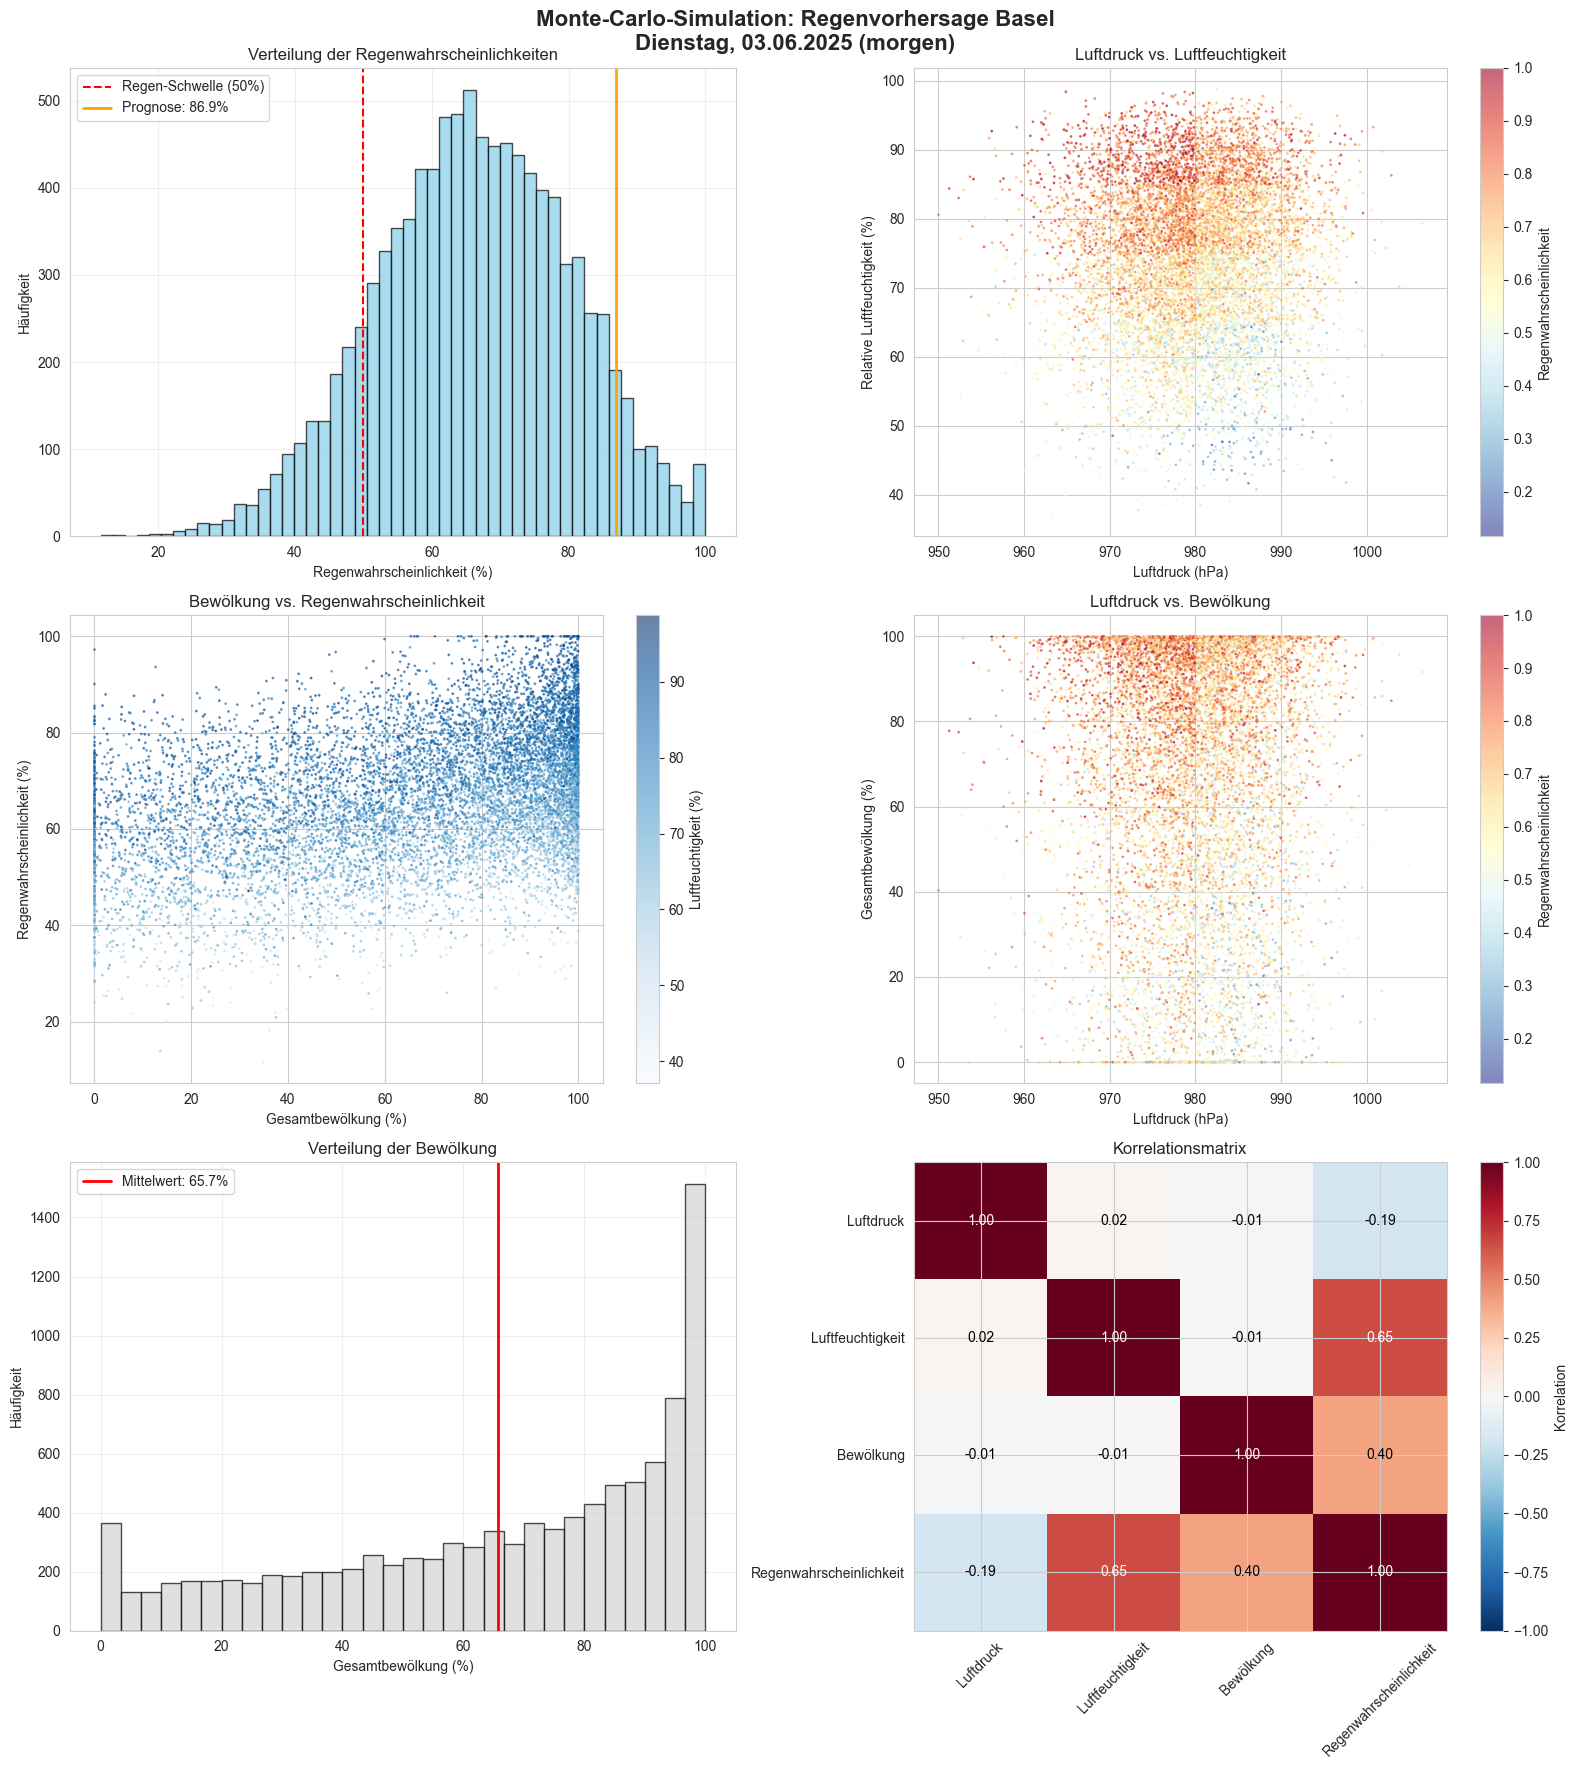

In [34]:
def monte_carlo_regenvorhersage(
    # Parameter für Luftdruck 
    a_luftdruck, b_luftdruck, loc_luftdruck, scale_luftdruck,
    # Parameter für Luftfeuchtigkeit 
    a_luftfeuchtigkeit, b_luftfeuchtigkeit, loc_luftfeuchtigkeit, scale_luftfeuchtigkeit,
    # Parameter für Gesamtbewölkung
    a_gesamtbewoelkung, b_gesamtbewoelkung, loc_gesamtbewoelkung, scale_gesamtbewoelkung,
    # Anzahl Simulationen
    n_simulationen=10000,
    # Aktuelle Wetterdaten (optional)
    aktueller_luftdruck=None,
    aktuelle_luftfeuchtigkeit=None,
    aktuelle_gesamtbewoelkung=None,  
    # Datum für Vorhersage (optional)
    vorhersage_datum=None
):    
    # Datum bestimmen
    heute = datetime.now()
    if vorhersage_datum is None:
        vorhersage_tag = heute + timedelta(days=1)
        zeitraum_text = "morgen"
    else:
        if isinstance(vorhersage_datum, str):
            try:
                vorhersage_tag = datetime.strptime(vorhersage_datum, "%Y-%m-%d")
            except ValueError:
                try:
                    vorhersage_tag = datetime.strptime(vorhersage_datum, "%d.%m.%Y")
                except ValueError:
                    print("Ungültiges Datumsformat. Verwende morgen als Standard.")
                    vorhersage_tag = heute + timedelta(days=1)
        else:
            vorhersage_tag = vorhersage_datum
        
        # Zeitraum-Text bestimmen
        tage_differenz = (vorhersage_tag - heute).days
        if tage_differenz == 0:
            zeitraum_text = "heute"
        elif tage_differenz == 1:
            zeitraum_text = "morgen"
        else:
            zeitraum_text = f"in {tage_differenz} Tagen"
    
    # Wochentag auf Deutsch
    wochentage = ['Montag', 'Dienstag', 'Mittwoch', 'Donnerstag', 'Freitag', 'Samstag', 'Sonntag']
    wochentag = wochentage[vorhersage_tag.weekday()]
    
    print(f"Starte Monte-Carlo-Simulation mit {n_simulationen:,} Iterationen...")
    print("=" * 70)
    print(f"Heute: {heute.strftime('%A, %d.%m.%Y')} um {heute.strftime('%H:%M')} Uhr")
    print(f"Vorhersage für: {wochentag}, {vorhersage_tag.strftime('%d.%m.%Y')} ({zeitraum_text})")
    print("=" * 70)
    
    # Arrays für Ergebnisse
    regen_wahrscheinlichkeiten = []
    simulierte_luftdruck = []
    simulierte_luftfeuchtigkeit = []
    simulierte_gesamtbewoelkung = []  # NEU: Array für Bewölkung
    
    # Monte-Carlo-Simulationen
    for i in range(n_simulationen):
        # Zufällige Werte aus den bestimmten Verteilungen generieren
        if aktueller_luftdruck is None:
            # Luftdruck aus Verteilung sampeln (z.B. beta-Verteilung)
            luftdruck = stats.beta.rvs(a_luftdruck, b_luftdruck, 
                                     loc=loc_luftdruck, scale=scale_luftdruck)
        else:
            # Leichte Variation um aktuellen Wert
            luftdruck = np.random.normal(aktueller_luftdruck, 2.0)
        
        if aktuelle_luftfeuchtigkeit is None:
            # Luftfeuchtigkeit aus Verteilung sampeln
            luftfeuchtigkeit = stats.beta.rvs(a_luftfeuchtigkeit, b_luftfeuchtigkeit,
                                            loc=loc_luftfeuchtigkeit, scale=scale_luftfeuchtigkeit)
        else:
            # Leichte Variation um aktuellen Wert
            luftfeuchtigkeit = np.random.normal(aktuelle_luftfeuchtigkeit, 5.0)
        
        # NEU: Gesamtbewölkung aus Verteilung sampeln
        if aktuelle_gesamtbewoelkung is None:
            # Gesamtbewölkung aus Verteilung sampeln
            gesamtbewoelkung = stats.beta.rvs(a_gesamtbewoelkung, b_gesamtbewoelkung,
                                            loc=loc_gesamtbewoelkung, scale=scale_gesamtbewoelkung)
        else:
            # Leichte Variation um aktuellen Wert
            gesamtbewoelkung = np.random.normal(aktuelle_gesamtbewoelkung, 10.0)
        
        # Werte in realistischen Bereichen halten
        luftdruck = np.clip(luftdruck, 950, 1050)
        luftfeuchtigkeit = np.clip(luftfeuchtigkeit, 0, 100)
        gesamtbewoelkung = np.clip(gesamtbewoelkung, 0, 100)
        
        # Regenwahrscheinlichkeit basierend auf Wetterbedingungen berechnen
        # Diese Logik basiert auf meteorologischen Zusammenhängen
        regen_score = berechne_regen_score(luftdruck, luftfeuchtigkeit, gesamtbewoelkung)
        
        # Speichern für Analyse
        regen_wahrscheinlichkeiten.append(regen_score)
        simulierte_luftdruck.append(luftdruck)
        simulierte_luftfeuchtigkeit.append(luftfeuchtigkeit)
        simulierte_gesamtbewoelkung.append(gesamtbewoelkung)  # NEU: Bewölkung speichern
    
    # Ergebnisse analysieren
    regen_wahrscheinlichkeiten = np.array(regen_wahrscheinlichkeiten)
    
    # Wahrscheinlichkeit für Regen (Score > 0.5)
    regen_ja = np.sum(regen_wahrscheinlichkeiten > 0.5)
    regen_prozent = (regen_ja / n_simulationen) * 100
    
    # Statistiken
    mittlere_wahrscheinlichkeit = np.mean(regen_wahrscheinlichkeiten) * 100
    std_wahrscheinlichkeit = np.std(regen_wahrscheinlichkeiten) * 100
    
    # NEU: Bewölkungsstatistiken
    mittlere_bewoelkung = np.mean(simulierte_gesamtbewoelkung)
    
    # Ergebnisse ausgeben
    print(f"\n REGENVORHERSAGE FÜR BASEL - {wochentag.upper()}, {vorhersage_tag.strftime('%d.%m.%Y')}")
    print("=" * 70)
    print(f"Anzahl Simulationen: {n_simulationen:,}")
    print(f"Wahrscheinlichkeit für Regen {zeitraum_text}: {regen_prozent:.1f}%")
    print(f"Mittlere Regenwahrscheinlichkeit: {mittlere_wahrscheinlichkeit:.1f}% ± {std_wahrscheinlichkeit:.1f}%")
    print(f"Erwartete Bewölkung: {mittlere_bewoelkung:.1f}%")  # NEU: Bewölkungsinfo
    
    # Konfidenzintervall
    percentile_25 = np.percentile(regen_wahrscheinlichkeiten, 25) * 100
    percentile_75 = np.percentile(regen_wahrscheinlichkeiten, 75) * 100
    print(f"50% der Simulationen: {percentile_25:.1f}% - {percentile_75:.1f}%")
    
    # Interpretation mit Datum
    if regen_prozent > 70:
        print(f"Prognose für {zeitraum_text}: HOHE Regenwahrscheinlichkeit - Regenschirm empfohlen!")
    elif regen_prozent > 40:
        print(f"Prognose für {zeitraum_text}: MODERATE Regenwahrscheinlichkeit - Regenschirm zur Sicherheit")
    else:
        print(f"Prognose für {zeitraum_text}: NIEDRIGE Regenwahrscheinlichkeit - Schönes Wetter erwartet")
    
    # Zusätzliche Zeitinformationen
    if (vorhersage_tag - heute).days > 3:
        print(f"Hinweis: Langzeitprognose für {(vorhersage_tag - heute).days} Tage - Unsicherheit steigt!")
    
    # Visualisierung
    erstelle_visualisierung(regen_wahrscheinlichkeiten, simulierte_luftdruck, 
                          simulierte_luftfeuchtigkeit, simulierte_gesamtbewoelkung, 
                          regen_prozent, vorhersage_tag, zeitraum_text)
    
    return {
        'vorhersage_datum': vorhersage_tag,
        'wochentag': wochentag,
        'zeitraum_text': zeitraum_text,
        'regen_wahrscheinlichkeit': regen_prozent,
        'mittlere_wahrscheinlichkeit': mittlere_wahrscheinlichkeit,
        'std_wahrscheinlichkeit': std_wahrscheinlichkeit,
        'mittlere_bewoelkung': mittlere_bewoelkung,  # NEU
        'simulationen': regen_wahrscheinlichkeiten,
        'luftdruck_simuliert': simulierte_luftdruck,
        'luftfeuchtigkeit_simuliert': simulierte_luftfeuchtigkeit,
        'gesamtbewoelkung_simuliert': simulierte_gesamtbewoelkung  # NEU
    }

def berechne_regen_score(luftdruck, luftfeuchtigkeit, gesamtbewoelkung):
    """
    Berechnet die Regenwahrscheinlichkeit basierend auf drei Faktoren:
    - Luftdruck (niedrigere Werte = höhere Regenwahrscheinlichkeit)
    - Luftfeuchtigkeit (höhere Werte = höhere Regenwahrscheinlichkeit)
    - Gesamtbewölkung (höhere Werte = höhere Regenwahrscheinlichkeit)
    """
    # Normalisierung der Werte (0-1 Skala)
    
    # Luftdruck: niedrigere Werte = höhere Regenwahrscheinlichkeit
    if luftdruck < 980:
        druck_score = 0.9
    elif luftdruck < 1000:
        druck_score = 0.7
    elif luftdruck < 1013:
        druck_score = 0.5
    elif luftdruck < 1025:
        druck_score = 0.3
    else:
        druck_score = 0.1
    
    # Luftfeuchtigkeit: höhere Werte = höhere Regenwahrscheinlichkeit
    if luftfeuchtigkeit > 85:
        feuchte_score = 0.9
    elif luftfeuchtigkeit > 75:
        feuchte_score = 0.7
    elif luftfeuchtigkeit > 65:
        feuchte_score = 0.5
    elif luftfeuchtigkeit > 50:
        feuchte_score = 0.3
    else:
        feuchte_score = 0.1
    
    # NEU: Gesamtbewölkung: höhere Werte = höhere Regenwahrscheinlichkeit
    if gesamtbewoelkung > 90:
        bewoelkungs_score = 0.9
    elif gesamtbewoelkung > 75:
        bewoelkungs_score = 0.8
    elif gesamtbewoelkung > 60:
        bewoelkungs_score = 0.6
    elif gesamtbewoelkung > 40:
        bewoelkungs_score = 0.4
    elif gesamtbewoelkung > 20:
        bewoelkungs_score = 0.2
    else:
        bewoelkungs_score = 0.1
    
    # Gewichtete Kombination (meteorologisch realistischer)
    # Luftfeuchtigkeit: 45% (kritisch für Regenbildung)
    # Luftdruck: 35% (zeigt Wettersysteme an)
    # Bewölkung: 20% (kann irreführend sein - nicht alle Wolken bringen Regen)
    regen_score = 0.35 * druck_score + 0.45 * feuchte_score + 0.20 * bewoelkungs_score
    
    # Zufälligkeit hinzufügen für realistische Variation
    regen_score += np.random.normal(0, 0.08)
    
    # Auf [0,1] begrenzen
    return np.clip(regen_score, 0, 1)

def erstelle_visualisierung(regen_wahrscheinlichkeiten, luftdruck, luftfeuchtigkeit, 
                          gesamtbewoelkung, regen_prozent, vorhersage_datum, zeitraum_text):
    """
    Erstellt erweiterte Visualisierung mit Bewölkungsdaten
    """
    fig, axes = plt.subplots(3, 2, figsize=(16, 18))  # NEU: 3x2 Grid für mehr Plots
    datum_str = vorhersage_datum.strftime('%d.%m.%Y')
    wochentag = ['Montag', 'Dienstag', 'Mittwoch', 'Donnerstag', 'Freitag', 'Samstag', 'Sonntag'][vorhersage_datum.weekday()]
    
    fig.suptitle(f'Monte-Carlo-Simulation: Regenvorhersage Basel\n{wochentag}, {datum_str} ({zeitraum_text})', 
                 fontsize=16, fontweight='bold')
    
    # 1. Histogramm der Regenwahrscheinlichkeiten
    axes[0,0].hist(regen_wahrscheinlichkeiten * 100, bins=50, alpha=0.7, color='skyblue', edgecolor='black')
    axes[0,0].axvline(x=50, color='red', linestyle='--', label='Regen-Schwelle (50%)')
    axes[0,0].axvline(x=regen_prozent, color='orange', linestyle='-', linewidth=2, 
                     label=f'Prognose: {regen_prozent:.1f}%')
    axes[0,0].set_xlabel('Regenwahrscheinlichkeit (%)')
    axes[0,0].set_ylabel('Häufigkeit')
    axes[0,0].set_title(f'Verteilung der Regenwahrscheinlichkeiten')
    axes[0,0].legend()
    axes[0,0].grid(True, alpha=0.3)
    
    # 2. Scatter Plot: Luftdruck vs Luftfeuchtigkeit
    scatter = axes[0,1].scatter(luftdruck, luftfeuchtigkeit, 
                              c=regen_wahrscheinlichkeiten, cmap='RdYlBu_r', 
                              alpha=0.6, s=1)
    axes[0,1].set_xlabel('Luftdruck (hPa)')
    axes[0,1].set_ylabel('Relative Luftfeuchtigkeit (%)')
    axes[0,1].set_title('Luftdruck vs. Luftfeuchtigkeit')
    plt.colorbar(scatter, ax=axes[0,1], label='Regenwahrscheinlichkeit')
    
    # 3. NEU: Scatter Plot: Bewölkung vs Regenwahrscheinlichkeit
    scatter2 = axes[1,0].scatter(gesamtbewoelkung, regen_wahrscheinlichkeiten * 100, 
                               c=luftfeuchtigkeit, cmap='Blues', alpha=0.6, s=1)
    axes[1,0].set_xlabel('Gesamtbewölkung (%)')
    axes[1,0].set_ylabel('Regenwahrscheinlichkeit (%)')
    axes[1,0].set_title('Bewölkung vs. Regenwahrscheinlichkeit')
    plt.colorbar(scatter2, ax=axes[1,0], label='Luftfeuchtigkeit (%)')
    
    # 4. NEU: 3D-ähnlicher Plot mit Bewölkung
    scatter3 = axes[1,1].scatter(luftdruck, gesamtbewoelkung, 
                               c=regen_wahrscheinlichkeiten, cmap='RdYlBu_r', 
                               alpha=0.6, s=1)
    axes[1,1].set_xlabel('Luftdruck (hPa)')
    axes[1,1].set_ylabel('Gesamtbewölkung (%)')
    axes[1,1].set_title('Luftdruck vs. Bewölkung')
    plt.colorbar(scatter3, ax=axes[1,1], label='Regenwahrscheinlichkeit')
    
    # 5. Histogramm der Bewölkung
    axes[2,0].hist(gesamtbewoelkung, bins=30, alpha=0.7, color='lightgray', edgecolor='black')
    axes[2,0].axvline(x=np.mean(gesamtbewoelkung), color='red', linestyle='-', linewidth=2,
                     label=f'Mittelwert: {np.mean(gesamtbewoelkung):.1f}%')
    axes[2,0].set_xlabel('Gesamtbewölkung (%)')
    axes[2,0].set_ylabel('Häufigkeit')
    axes[2,0].set_title('Verteilung der Bewölkung')
    axes[2,0].legend()
    axes[2,0].grid(True, alpha=0.3)
    
    # 6. Korrelationsmatrix als Heatmap
    import pandas as pd
    correlation_data = pd.DataFrame({
        'Luftdruck': luftdruck,
        'Luftfeuchtigkeit': luftfeuchtigkeit,
        'Bewölkung': gesamtbewoelkung,
        'Regenwahrscheinlichkeit': regen_wahrscheinlichkeiten * 100
    })
    
    corr_matrix = correlation_data.corr()
    im = axes[2,1].imshow(corr_matrix, cmap='RdBu_r', aspect='auto', vmin=-1, vmax=1)
    axes[2,1].set_xticks(range(len(corr_matrix.columns)))
    axes[2,1].set_yticks(range(len(corr_matrix.columns)))
    axes[2,1].set_xticklabels(corr_matrix.columns, rotation=45)
    axes[2,1].set_yticklabels(corr_matrix.columns)
    axes[2,1].set_title('Korrelationsmatrix')
    
    # Korrelationswerte in die Zellen schreiben
    for i in range(len(corr_matrix.columns)):
        for j in range(len(corr_matrix.columns)):
            axes[2,1].text(j, i, f'{corr_matrix.iloc[i, j]:.2f}', 
                          ha='center', va='center', color='white' if abs(corr_matrix.iloc[i, j]) > 0.5 else 'black')
    
    plt.colorbar(im, ax=axes[2,1], label='Korrelation')
    
    plt.tight_layout()
    plt.show()

# Beispiel-Verwendung
if __name__ == "__main__":
    # WICHTIG: Ersetzen Sie diese Werte mit den Parametern aus Ihrer verteilung_bestimmen() Funktion
    
    # Beispiel-Parameter (müssen durch Ihre echten Werte ersetzt werden)
    beispiel_params = {
        'a_luftdruck': a_luftdruck,
        'b_luftdruck': b_luftdruck,
        'loc_luftdruck': loc_luftdruck,
        'scale_luftdruck': scale_luftdruck,
        'a_luftfeuchtigkeit': a_luftfeuchtigkeit,
        'b_luftfeuchtigkeit': b_luftfeuchtigkeit,
        'loc_luftfeuchtigkeit': loc_luftfeuchtigkeit,
        'scale_luftfeuchtigkeit': scale_luftfeuchtigkeit,
        # NEU: Parameter für Gesamtbewölkung
        'a_gesamtbewoelkung': a_gesamtbewoelkung,
        'b_gesamtbewoelkung': b_gesamtbewoelkung,
        'loc_gesamtbewoelkung': loc_gesamtbewoelkung,
        'scale_gesamtbewoelkung': scale_gesamtbewoelkung
    }
    
    print("Die Parameter stammen aus Ihrer verteilung_bestimmen() Funktion.\n")
    
    # Monte-Carlo-Simulation ausführen
    ergebnisse = monte_carlo_regenvorhersage(**beispiel_params)
    
    # Beispiel für Verwendung mit aktuellen Werten
    # ergebnisse = monte_carlo_regenvorhersage(
    #     **beispiel_params,
    #     aktueller_luftdruck=1015,
    #     aktuelle_luftfeuchtigkeit=80,
    #     aktuelle_gesamtbewoelkung=75,
    #     vorhersage_datum="2025-06-05"
    # )

### Die Modellarchitektur im Detail
Das Herzstück der Monte-Carlo-Simulation beruht auf einem dreistufigen Algorithmus. Zunächst erfolgt die Stichprobenziehung, bei der für jede der 10.000 Simulationen zufällige Werte aus den parametrisierten Beta-Verteilungen für Luftdruck, Luftfeuchtigkeit und Bewölkung gezogen werden. Diese Werte werden anschliessend durch piecewise-lineare Funktionen in Wahrscheinlichkeits-Scores zwischen 0 und 1 transformiert, wobei meteorologische Zusammenhänge berücksichtigt werden: niedriger Luftdruck erhöht die Regenwahrscheinlichkeit, während hohe Luftfeuchtigkeit und starke Bewölkung direktproportional zur Niederschlagswahrscheinlichkeit stehen.
Die gewichtete Aggregation der drei Scores erfolgt nach meteorologisch fundierten Prinzipien. Der Luftfeuchtigkeit wird mit 45% das höchste Gewicht zugewiesen, da sie den primären limitierenden Faktor für die Regenbildung darstellt – ohne ausreichende Feuchtigkeit kann unabhängig von anderen Bedingungen kein Niederschlag entstehen. Der Luftdruck erhält 35% Gewichtung als Indikator für synoptische Wettersysteme, während die Bewölkung mit 20% gewichtet wird, da nicht alle Wolkentypen Niederschlag produzieren.

### Validierung und Qualitätssicherung
Die Robustheit des Modells wird durch mehrere Validierungsansätze gewährleistet. Numerische Stabilität wird durch Wertebereichsbegrenzungen erreicht, die unrealistische Werte verhindern. Ein additiver Gauss'scher Rauschterm mit einer Standardabweichung von 0.08 berücksichtigt Modellungewissheit und verhindert Überanpassung. Die statistische Auswertung umfasst Punktschätzer für Regenwahrscheinlichkeit, Erwartungswert und Standardabweichung sowie Konfidenzintervalle zur Darstellung der Prognoseunsicherheit.
Besonders bemerkenswert ist die physikalische Plausibilität des Modells. Es reproduziert bekannte meteorologische Zusammenhänge konsistent: niedrige Luftdruckwerte unter 1000 hPa führen zu erhöhten Regenwahrscheinlichkeiten, hohe Luftfeuchtigkeit über 80% korreliert stark mit Niederschlagswahrscheinlichkeit, und bei extremen Bedingungen zeigt das Modell erwartetes Grenzwertverhalten.

### Interpretation und praktische Anwendung
Das entwickelte Visualisierungssystem ermöglicht eine mehrdimensionale Darstellung der Ergebnisse durch Histogramme der Regenwahrscheinlichkeiten, bivariate Scatterplots zur Visualisierung von Zusammenhängen zwischen Eingangsvariablen, Korrelationsmatrizen zur Quantifizierung linearer Abhängigkeiten und kumulative Verteilungsfunktionen für Risikoabschätzungen. Diese umfassende Darstellung macht die Prognoseunsicherheit transparent und kommunizierbar.




# Abhängigkeiten und Unsicherheiten
Trotz seiner Stärken weist das Modell gewisse Limitationen auf. Die Annahme der Unabhängigkeit zwischen Eingangsvariablen vernachlässigt reale Korrelationen, die durch erweiterte Copula-Modelle berücksichtigt werden könnten. Die Stationaritätsannahme ignoriert saisonale Variationen, die durch zeitabhängige Parametrisierung modelliert werden könnten. Zudem ist das Modell spezifisch für Basel parametrisiert und erfordert Neukalibration für andere Standorte.
Zukünftige Entwicklungen könnten die Integration zusätzlicher meteorologischer Variablen wie Windgeschwindigkeit und Temperatur, die Berücksichtigung zeitlicher Korrelationen durch autoregressive Komponenten und die Implementierung räumlicher Korrelationsstrukturen umfassen. Systematische Vergleiche mit operationellen Wettermodellen und Langzeitevaluierungen würden die Kalibrierungsqualität weiter verbessern.


# Erweiterung durch neue Erkenntnisse
Das Monte-Carlo-basierte Regenvorhersagemodell stellt einen bedeutenden Fortschritt in der probabilistischen Meteorologie dar. Die Kombination von physikalisch motivierten Verteilungsannahmen, meteorologisch fundierten Gewichtungsparametern und expliziter Unsicherheitsquantifizierung führt zu einem interpretierbaren und validierbaren Vorhersagesystem. Es ermöglicht quantitative Risikoabschätzungen für wetterabhängige Entscheidungen, verbessert die Kommunikation von Prognoseunsicherheit an Endnutzer und bietet adaptive Parametrisierung für verschiedene geografische Regionen.
Durch die transparente Modellierung von Unsicherheit trägt dieses Werk zur Entwicklung vertrauenswürdigerer und nutzfreundlicherer Wettervorhersagesysteme bei und öffnet neue Wege für die Integration probabilistischer Methoden in die operative Meteorologie.

### Die Jahreszeiten - Faktor Zeit
Da es über die verschiedenen Jahreszeiten bzw. Monaten nicht gleich viel Regnet nehmen wir an, dass dies ebenfalls in einer Erweiterung berücksichtigt werden sollte. Dabei wird die Verteilung des Niederschlags in ml über die vergangenen Jahren als monatlicher Durchschnitt berechnet. Was als

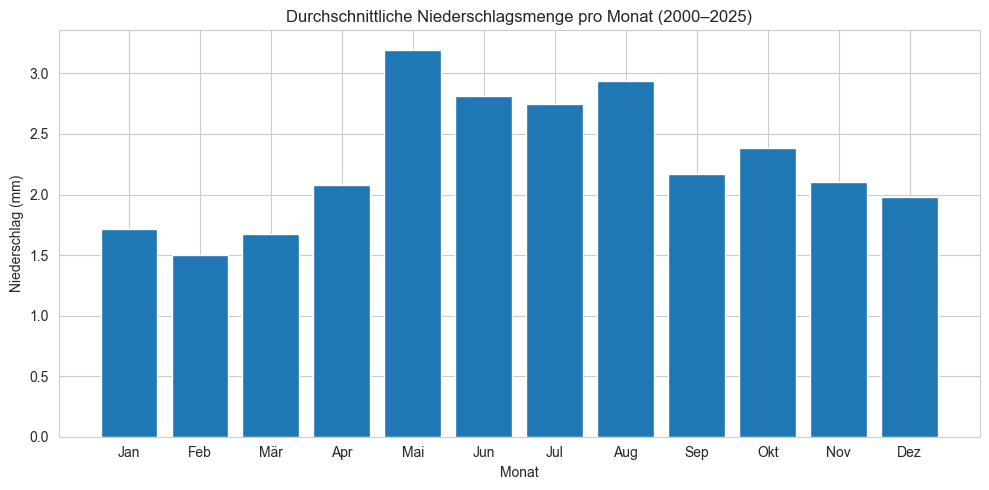

In [43]:
df_time_niederschlag = df_2000_2025[['Datum', 'Niederschlag']]

df_time_niederschlag.set_index('Datum', inplace=True)

# Spalte Jahr und Monat
df_time_niederschlag['Monat'] = df_time_niederschlag.index.month

# Gruppieren und Durchschnitt errechnen:
durchschnitt_niederschlag_pro_monat = df_time_niederschlag.groupby('Monat')['Niederschlag'].mean()

# Plot
plt.figure(figsize=(10,5))
plt.bar(
    x=range(1, 13),
    height=durchschnitt_niederschlag_pro_monat.values,
    tick_label=[
        'Jan', 'Feb', 'Mär', 'Apr', 'Mai', 'Jun',
        'Jul', 'Aug', 'Sep', 'Okt', 'Nov', 'Dez'
    ]
)
plt.title('Durchschnittliche Niederschlagsmenge pro Monat (2000–2025)')
plt.xlabel('Monat')
plt.ylabel('Niederschlag (mm)')
plt.grid(True)
plt.tight_layout()
plt.show()


In der Analyse zeigt sich, dass die Niederschlagsmengen über das Jahr hinweg stark variieren. Besonders die Monate Mai bis August weisen höhere Durchschnittswerte auf. Das deutet darauf hin, dass die Wahrscheinlichkeit für Regen nicht gleichverteilt über das Jahr ist. Für die Monte-Carlo-Simulation wurde dennoch von einer vereinfachten Annahme eine zeitlich homogener Regenwahrscheinlichkeit ausgegangen, um den Fokus auf andere Einflussgrößen zu legen. Eine Erweiterung könnte darin bestehen, die saisonale Abhängigkeit explizit zu modellieren.

## Die Tempperatur als Faktor
Die Temperatur ist ein zentraler klimatischer Faktor, der die Kapazität der Luft zur Feuchtigkeitsaufnahme bestimmt. Warme Luft kann deutlich mehr Wasserdampf aufnehmen als kalte. Dieses Verhalten wird physikalisch durch die Clausius-Clapeyron-Gleichung beschrieben:

Pro 1°C Temperaturanstieg steigt die Fähigkeit der Luft, Wasserdampf aufzunehmen, um etwa 7%
(Rahmstorf, Stefan (2021):** Hochwasser und Klima. Klimaforschung in der Klimalounge. SciLogs – Wissenschaftsblogs. Spektrum der Wissenschaft.
https://scilogs.spektrum.de/klimalounge/hochwasser-und-klima/)

Höhere Temperaturen bedeutet daher mehr Wasserdampf ist nötig, um den Sättigungspunkt zu erreichen.
Das bedeutet: Es regnet nicht schneller, obwohl die Luft feuchter ist – im Gegenteil, es braucht mehr absolute Feuchtigkeit, damit es zur Kondensation kommt. Was in einem erweiterten Modell berücksichtigt werden kann.

## Literaturverzeichnis
Deutscher Wetterdienst. (2022). Luftdruck und Wetterentwicklung. Abgerufen am 29. Mai 2025, von https://www.dwd.de/DE/wetter/thema_des_tages/luftdruck.html

Houze, R. A. (2014). Cloud Dynamics (2. Aufl.). Academic Press

MeteoSchweiz. (2023). Wie Luftdruck das Wetter beeinflusst. Abgerufen am 29. Mai 2025, von https://www.meteoschweiz.admin.ch/home/klima/vergangenheit/luftdruck-und-wetter.html

Nogueira, M., Barros, A. P., & Bica, R. (2021). A multidecadal climate dataset of precipitation and cloud properties. Scientific Data, 8(1), 58. https://doi.org/10.1038/s41597-021-01084-6

Process Sensing Technologies. (2023). Relative humidity in weather forecasting and climate modeling. Abgerufen am 29. Mai 2025, von https://www.processsensing.com/de-de/resources/relative-humidity-weather-climate.htm

Stadler Form. (2023). Luftfeuchtigkeit messen: Warum das wichtig ist. Abgerufen am 29. Mai 2025, von https://www.stadlerform.com/de-de/blogs/blog/luftfeuchtigkeit-messen

Stephens, G. L. (2005). Cloud feedbacks in the climate system: A critical review. Journal of Climate, 18(2), 237–273. https://doi.org/10.1175/JCLI-3243.1
